In [1]:
#install.packages("caret")
#install.packages("plotly")
library(class)  # For KNN classification
library(caret)  # For train-test split
library(ggplot2)  # For visualization
library(plotly)
library(dplyr)


Loading required package: ggplot2

Loading required package: lattice


Attaching package: ‘caret’


The following object is masked from ‘package:httr’:

    progress



Attaching package: ‘plotly’


The following object is masked from ‘package:ggplot2’:

    last_plot


The following object is masked from ‘package:stats’:

    filter


The following object is masked from ‘package:graphics’:

    layout


The following object is masked from ‘package:httr’:

    config



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [2]:
#Read data from uploaded file (kaggle input) 
#Fisher, R. A. (1936). The use of multiple measurements in taxonomic problems. 
#Annals of Eugenics, 7(2), 179–188. DOI:10.1111/j.1469-1809.1936.tb02137.x

#Downloaded and check locally, and then uploaded again
flower_iris <- read.table("/kaggle/input/iris-dataset/IRIS.csv", sep=',', header=T)
#View(flower_iris)
head(flower_iris)
class(flower_iris)
str(flower_iris)

,sepal_length,sepal_width,petal_length,petal_width,species
,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,5.1,3.5,1.4,0.2,Iris-setosa
2,4.9,3.0,1.4,0.2,Iris-setosa
3,4.7,3.2,1.3,0.2,Iris-setosa
4,4.6,3.1,1.5,0.2,Iris-setosa
5,5.0,3.6,1.4,0.2,Iris-setosa
6,5.4,3.9,1.7,0.4,Iris-setosa


[1] "data.frame"

'data.frame':	150 obs. of  5 variables:
 $ sepal_length: num  5.1 4.9 4.7 4.6 5 5.4 4.6 5 4.4 4.9 ...
 $ sepal_width : num  3.5 3 3.2 3.1 3.6 3.9 3.4 3.4 2.9 3.1 ...
 $ petal_length: num  1.4 1.4 1.3 1.5 1.4 1.7 1.4 1.5 1.4 1.5 ...
 $ petal_width : num  0.2 0.2 0.2 0.2 0.2 0.4 0.3 0.2 0.2 0.1 ...
 $ species     : chr  "Iris-setosa" "Iris-setosa" "Iris-setosa" "Iris-setosa" ...


In [3]:
#Selecting Sepal.Length, Sepal.Width, Petal.Length as features with slicing method
features <- flower_iris[, 1:3]  
target <- flower_iris$Species

In [4]:
#Normalize the features
normalize <- function(x) {
  return((x - min(x)) / (max(x) - min(x)))
}

features <- as.data.frame(lapply(features, normalize))

# Convert target to factor
target <- as.factor(flower_iris$species)

In [5]:
#Split data
set.seed(123) # For reproducibility
train_index <- createDataPartition(target, p = 0.8, list = FALSE) 

#Indexing for Train and Test
train_features <- features[train_index, , drop = FALSE]
test_features  <- features[-train_index, , drop = FALSE]
train_target   <- target[train_index]
test_target    <- target[-train_index]

#print the split result (80% for train & 20% for test)
print(dim(train_features)) 
print(dim(test_features))   


[1] 120   3
[1] 30  3


In [6]:
#Euclidean Distance Function
euclidean_distance <- function(x1, x2) {
  return(sqrt(sum((x1 - x2)^2)))
}

#Manual KNN Function
manual_knn <- function(train_features, train_target, test_features, k) {
  predictions <- c()
  
  for (i in 1:nrow(test_features)) {
    distances <- apply(train_features, 1, function(row) euclidean_distance(row, test_features[i, ]))
    
    # Get indices of the k nearest neighbors
    nearest_indices <- order(distances)[1:k]
    
    # Get the labels of the nearest neighbors
    nearest_labels <- train_target[nearest_indices]
    
    # Predict the most frequent class (majority vote)
    predicted_class <- names(which.max(table(nearest_labels)))
    predictions <- c(predictions, predicted_class)
  }
  
  return(as.factor(predictions))
}



# Sorting distances
sorted_distances = sorted(distances, key=lambda x: x[1])

In [7]:
#Evaluate Accuracy for K = 1 to 5
for (k in 1:5) {
  predicted_labels <- manual_knn(train_features, train_target, test_features, k)
  accuracy <- mean(predicted_labels == test_target) * 100
  cat(sprintf("Accuracy for K = %d: %.2f%%\n", k, accuracy))
}

Accuracy for K = 1: 93.33%
Accuracy for K = 2: 86.67%
Accuracy for K = 3: 86.67%
Accuracy for K = 4: 90.00%
Accuracy for K = 5: 86.67%


[1] "Confusion Matrix for Best K:"
                 Actual
Predicted         Iris-setosa Iris-versicolor Iris-virginica
  Iris-setosa              10               0              0
  Iris-versicolor           0               9              1
  Iris-virginica            0               1              9


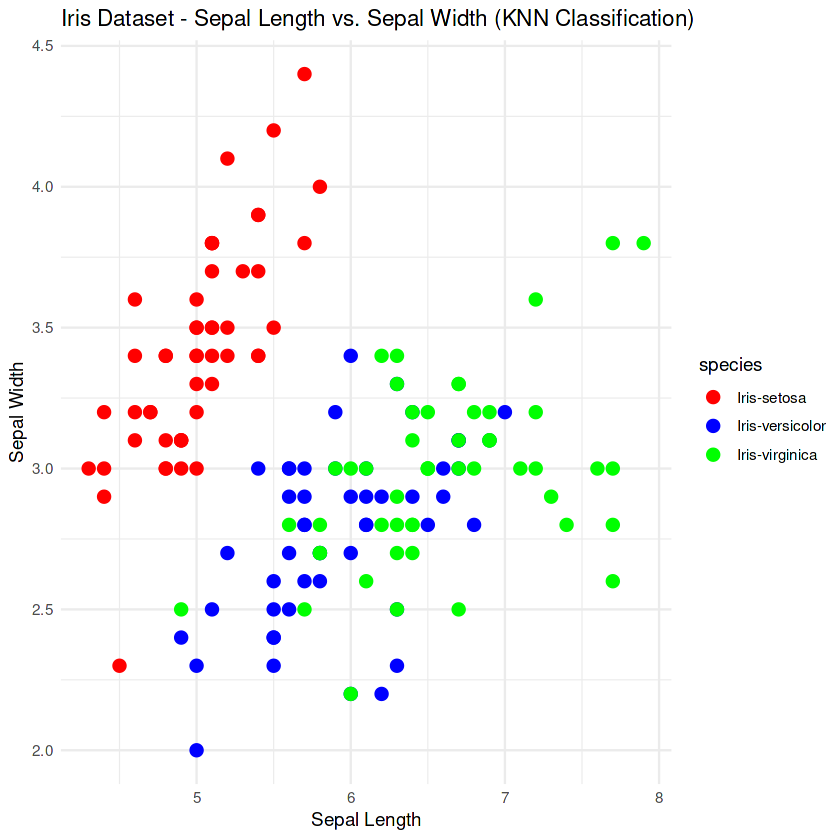

In [8]:
#Confusion Matrix for Best K Value
best_k <- 1
predicted_best <- manual_knn(train_features, train_target, test_features, best_k)
conf_matrix <- table(Predicted = predicted_best, Actual = test_target)
print("Confusion Matrix for Best K:")
print(conf_matrix)

#Plot the Results
ggplot(flower_iris, aes(x = sepal_length, y = sepal_width, color = species)) +
  geom_point(size = 3) +
  theme_minimal() +
  labs(title = "Iris Dataset - Sepal Length vs. Sepal Width (KNN Classification)",
       x = "Sepal Length",
       y = "Sepal Width") +
  scale_color_manual(values = c("red", "blue", "green"))
